# Student Dropout & Academic Success - Classification Project
## Notebook 2: Algorithm Selection -> Training -> Evaluation -> Hyperparameter Tuning

**Covers ML process steps 4, 5 and 6.** The **test set is not used anywhere in this notebook** - it stays locked until Notebook 3, so our final score will be honest.

> **Reminder from Notebook 1:** we split the students into *train* (70%, the model learns from it), *validation* (15%, we compare and tune models on it) and *test* (15%, the final exam).

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 200)

SEED = 42
NJ = os.cpu_count()
FIG, MODELS = Path("figures"), Path("models")
FIG.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
CLASSES = ["Dropout", "Enrolled", "Graduate"]            # encoded as 0, 1, 2
PALETTE = {"Dropout": "#d1495b", "Enrolled": "#edae49", "Graduate": "#00798c"}
TARGET_F1, TARGET_RECALL = 0.70, 0.75                    # success criteria from Notebook 1

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

# ---- load the splits created in Notebook 1 (train and validation only!) ----
S = Path("data/splits")
train, val = pd.read_csv(S / "train.csv"), pd.read_csv(S / "val.csv")
groups = json.load(open(S / "feature_groups.json"))
X_train, y_train = train.drop(columns="target"), train["target"].values
X_val, y_val = val.drop(columns="target"), val["target"].values
print("train:", X_train.shape, "| validation:", X_val.shape)

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: (3096, 42) | validation: (664, 42)


## 0. Two scenarios: "full" vs. "early warning"
Notebook 1 warned that 2nd-semester results only exist **late** in the first year. A university that wants to warn students *early* can only use background information plus **1st-semester** results. So we build every model twice:

| Scenario | Features used | Use case |
|---|---|---|
| **full** | all 42 features | Best possible accuracy, but the information arrives late |
| **early** | everything except 2nd-semester data (and features derived from it) | A realistic *early-warning* system |

Comparing them tells us honestly how much the late information is worth.

In [2]:
LATE = [c for c in X_train.columns if "2nd_sem" in c] + \
       ["sem2_approval_rate", "total_units_approved", "total_units_enrolled", "overall_approval_rate", "grade_change"]
SCEN = {"full": list(X_train.columns),
        "early": [c for c in X_train.columns if c not in LATE]}
for k, v in SCEN.items():
    print(f"{k:>5}: {len(v)} features")
print("\nRemoved for the early scenario:", len(LATE), "features, e.g.", LATE[:4])

def make_pipe(cols, estimator):
    """Preprocessing + model glued into ONE object (a 'Pipeline').
    Because they are glued together, the scaler/encoder is always fitted on training data only,
    even inside cross-validation - this prevents data leakage automatically."""
    pre = ColumnTransformer([
        ("num", StandardScaler(), [c for c in groups["numeric"] if c in cols]),
        ("bin", "passthrough", [c for c in groups["binary"] if c in cols]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), [c for c in groups["nominal"] if c in cols]),
    ])
    return Pipeline([("prep", pre), ("model", estimator)])

 full: 42 features
early: 31 features

Removed for the early scenario: 11 features, e.g. ['curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved']


---
# Step 4 - Algorithm Selection

### What is an algorithm vs. a model?
* An **algorithm** is a *recipe* for learning from data (e.g. "Random Forest").
* A **model** is what comes out after the recipe has studied the training data: a fitted object that can make predictions.

There is no single best algorithm for every problem, so we try a **range of families** and let the validation set decide. We weigh three things: **accuracy**, **interpretability** (can a human understand why?) and **computational cost**.

| Algorithm | Idea in plain words | Strengths | Weaknesses | Needs scaling? |
|---|---|---|---|---|
| **Logistic Regression** | Gives each feature a weight, adds them up into a score for each class | Fast, very **interpretable**, great *baseline* | Only draws straight-line boundaries | Yes |
| **Decision Tree** | A flowchart of yes/no questions ("tuition paid? approved units > 3?") | Easy to read and draw | One tree **memorises** training data easily (overfits) | No |
| **Random Forest** | Hundreds of different trees each **vote**; majority wins | Accurate, robust, hard to overfit, handles messy data | Slower, harder to interpret | No |
| **XGBoost** (gradient boosting) | Trees built **one after another**, each fixing the previous trees' mistakes | Often the most accurate on tables like ours | Many settings to tune | No |
| **SVM** (RBF kernel) | Finds the boundary with the widest possible "safety margin" between classes | Strong on medium-sized data | Slow on big data, hard to interpret | Yes |
| **Neural Network (MLP)** | Layers of tiny connected "neurons" that learn combinations of features | Can learn complex patterns | Needs more data, a black box | Yes |

### The baseline - why we start with a "dumb" model
A **baseline** is the simplest possible predictor. Any real model must beat it, otherwise it is not learning anything useful. Ours always predicts the most common class (Graduate).

### Parameters vs. hyperparameters
* **Parameters** are numbers the model *learns by itself* from the data (e.g. a weight in Logistic Regression).
* **Hyperparameters** are *settings we choose before training* - the knobs of the recipe (e.g. "how many trees?", "how deep may a tree grow?"). Tuning them is Step 6.

---
# Step 5 - Model Development and Training

### 5.1 Evaluation metrics (how we score a model)
A model answers each student with a class. The **confusion matrix** counts right and wrong answers: rows = what really happened, columns = what the model predicted.

For one class, say **Dropout**:
* **Precision** = of the students we *flagged* as Dropout, how many really dropped out? (low precision = many false alarms)
* **Recall** = of the students who *really* dropped out, how many did we catch? (low recall = we miss at-risk students)
* **F1-score** = a single number that balances precision and recall (it is low if *either* is low).
* **Macro average** = compute the score for each of the 3 classes, then take the plain average. Small classes count as much as big ones.
* **ROC-AUC (one-vs-rest)** = for each class, how well does the model's *probability* rank true members above non-members? 0.5 = coin flip, 1.0 = perfect.

We train on the **training** set and score on **both** training and validation data. A big gap (great on training, much worse on validation) signals **overfitting**.

In [3]:
def evaluate(pipe, X, y):
    """Return all metrics for a fitted pipeline."""
    proba = pipe.predict_proba(X)
    pred = proba.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y, pred),
        "macro_precision": precision_score(y, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y, pred, average="macro"),
        "macro_f1": f1_score(y, pred, average="macro"),
        "dropout_recall": recall_score(y, pred, labels=[0], average=None)[0],
        "roc_auc": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
    }

def fit_pipe(pipe, X, y, balanced_weights=False):
    """Fit; optionally weight each student so small classes count more ('balanced')."""
    if balanced_weights:
        pipe.fit(X, y, model__sample_weight=compute_sample_weight("balanced", y))
    else:
        pipe.fit(X, y)
    return pipe

def zoo():
    xgb = dict(n_estimators=300, learning_rate=0.1, max_depth=4, eval_metric="mlogloss",
               tree_method="hist", random_state=SEED, n_jobs=NJ)
    return {   # name -> (estimator, use balanced sample weights?)
        "Baseline (always Graduate)": (DummyClassifier(strategy="most_frequent"), False),
        "Logistic Regression": (LogisticRegression(max_iter=2000), False),
        "Logistic Regression (balanced)": (LogisticRegression(max_iter=2000, class_weight="balanced"), False),
        "Decision Tree": (DecisionTreeClassifier(random_state=SEED), False),
        "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=NJ), False),
        "Random Forest (balanced)": (RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                            random_state=SEED, n_jobs=NJ), False),
        "XGBoost": (XGBClassifier(**xgb), False),
        "XGBoost (balanced)": (XGBClassifier(**xgb), True),
        "SVM (RBF)": (SVC(probability=True, random_state=SEED), False),
        "Neural Net (MLP)": (MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                           max_iter=500, random_state=SEED), False),
    }
print(len(zoo()), "candidate models defined")

10 candidate models defined


### 5.2 Train every candidate (default settings) and compare on the validation set
"(balanced)" means we told the model that mistakes on the small classes (Dropout, Enrolled) cost more, to counter the class imbalance we found in Notebook 1.

In [4]:
rows = []
for scen, cols in SCEN.items():
    for name, (est, bal) in zoo().items():
        t0 = time.time()
        pipe = fit_pipe(make_pipe(cols, est), X_train[cols], y_train, bal)
        sec = time.time() - t0
        tr, va = evaluate(pipe, X_train[cols], y_train), evaluate(pipe, X_val[cols], y_val)
        rows.append({"scenario": scen, "model": name, "train_macro_f1": tr["macro_f1"],
                     **{f"val_{k}": v for k, v in va.items()}, "seconds": sec})
    print(f"finished scenario: {scen}")

res = pd.DataFrame(rows)
res["overfit_gap"] = res["train_macro_f1"] - res["val_macro_f1"]
show = ["model", "train_macro_f1", "val_accuracy", "val_macro_f1", "val_dropout_recall", "val_roc_auc", "overfit_gap", "seconds"]
for scen in SCEN:
    print(f"\n=== Scenario: {scen} ===")
    display(res[res.scenario == scen][show].sort_values("val_macro_f1", ascending=False).round(3).reset_index(drop=True))

finished scenario: full


finished scenario: early

=== Scenario: full ===


,model,train_macro_f1,val_accuracy,val_macro_f1,val_dropout_recall,val_roc_auc,overfit_gap,seconds
0,XGBoost,0.932,0.768,0.710,0.728,0.884,0.222,1.531
1,XGBoost (balanced),0.924,0.744,0.707,0.704,0.880,0.217,0.899
2,Logistic Regression,0.744,0.773,0.703,0.751,0.874,0.040,5.695
3,Random Forest (balanced),1.000,0.767,0.692,0.718,0.878,0.308,1.202
4,Neural Net (MLP),0.772,0.767,0.688,0.732,0.869,0.083,0.616
5,SVM (RBF),0.776,0.765,0.688,0.746,0.875,0.088,2.152
6,Logistic Regression (balanced),0.763,0.723,0.686,0.700,0.870,0.077,7.620
7,Random Forest,1.000,0.747,0.660,0.718,0.878,0.340,0.677
8,Decision Tree,1.000,0.678,0.614,0.681,0.724,0.386,0.076
9,Baseline (always Graduate),0.222,0.500,0.222,0.000,0.500,-0.000,0.033



=== Scenario: early ===


,model,train_macro_f1,val_accuracy,val_macro_f1,val_dropout_recall,val_roc_auc,overfit_gap,seconds
0,Neural Net (MLP),0.809,0.739,0.675,0.695,0.848,0.134,0.637
1,XGBoost (balanced),0.881,0.706,0.669,0.671,0.857,0.212,0.354
2,XGBoost,0.884,0.727,0.665,0.700,0.857,0.218,0.392
3,Logistic Regression,0.715,0.745,0.662,0.718,0.854,0.053,5.129
4,Logistic Regression (balanced),0.724,0.688,0.649,0.667,0.851,0.075,4.483
5,SVM (RBF),0.770,0.735,0.645,0.704,0.858,0.125,2.042
6,Random Forest,1.000,0.736,0.624,0.718,0.857,0.376,0.676
7,Random Forest (balanced),1.000,0.730,0.622,0.714,0.855,0.378,1.013
8,Decision Tree,1.000,0.652,0.588,0.634,0.705,0.412,0.061
9,Baseline (always Graduate),0.222,0.500,0.222,0.000,0.500,-0.000,0.023


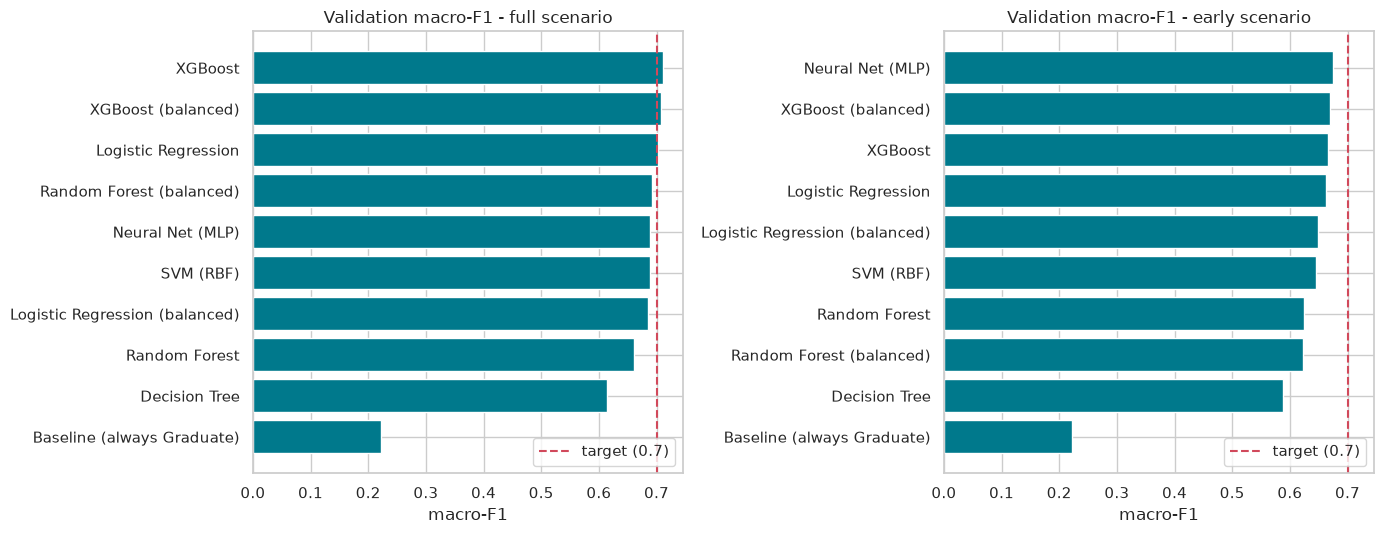

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
for ax, scen in zip(axes, SCEN):
    d = res[res.scenario == scen].sort_values("val_macro_f1")
    ax.barh(d["model"], d["val_macro_f1"], color="#00798c")
    ax.axvline(TARGET_F1, color="#d1495b", ls="--", label=f"target ({TARGET_F1})")
    ax.set_title(f"Validation macro-F1 - {scen} scenario"); ax.set_xlabel("macro-F1")
    ax.legend(loc="lower right")
save("09_model_comparison_macro_f1")
plt.show()

### What the comparison shows
* **The baseline proves the problem is real:** "always Graduate" gets 50% accuracy but a macro-F1 of only **0.22** and catches **0 dropouts**.
* **Many models are close together.** In the *full* scenario the six best models score between 0.688 and 0.710 macro-F1 (XGBoost 0.710, XGBoost-balanced 0.707, Logistic Regression 0.703). With only 664 validation students, differences of ~0.01-0.02 are **within normal random noise**, so we should not over-claim that one is truly better.
* **A simple model nearly ties the complex ones.** Logistic Regression (0.703) is almost as good as XGBoost (0.710) and is far easier to explain. This suggests that most of the signal is simple and "additive" (more passed units -> less risk).
* **Overfitting is clearly visible.** Decision Tree and Random Forest reach a training macro-F1 of **1.00** (they memorised the training students) but only 0.61-0.69 on validation, a gap of 0.31-0.39. XGBoost also overfits (0.93 vs 0.71). By contrast Logistic Regression (gap 0.04), MLP (0.08) and SVM (0.09) are well balanced.
* **Class weights are not magic:** "balanced" helped Random Forest (0.660 -> 0.692) but *hurt* Logistic Regression (0.703 -> 0.686).
* **The early scenario is only a little worse:** its best default model scores 0.675 versus 0.710 for the full scenario - roughly **0.035 lost** by not knowing 2nd-semester results.

### 5.3 Underfitting vs. overfitting
* **Underfitting:** the model is too simple - it does badly on *both* training and validation data (it has not learned the pattern).
* **Overfitting:** the model is too complex - it does great on training data but worse on validation data (it memorised instead of learning).
* **Good fit:** good on both, with a small gap.

The `overfit_gap` column above (training score minus validation score) measures this. A classic demonstration is a **Decision Tree**: the deeper we let it grow, the more it can memorise. We plot training vs. validation score as depth increases.

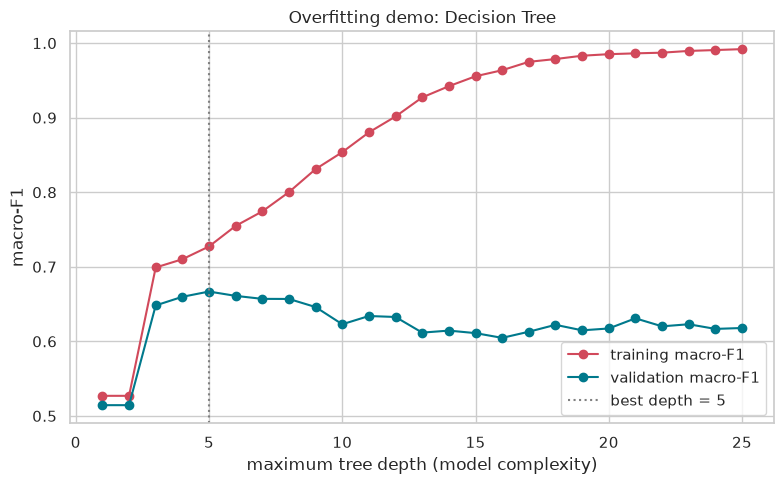

Depth 1: train 0.53 / val 0.51   |   best depth 5: val 0.67   |   depth 25: train 0.99 / val 0.62


In [6]:
cols = SCEN["full"]
pre = make_pipe(cols, None).named_steps["prep"].fit(X_train[cols])
Xt, Xv = pre.transform(X_train[cols]), pre.transform(X_val[cols])

depths = list(range(1, 26))
tr_s, va_s = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(Xt, y_train)
    tr_s.append(f1_score(y_train, tree.predict(Xt), average="macro"))
    va_s.append(f1_score(y_val, tree.predict(Xv), average="macro"))

best_d = depths[int(np.argmax(va_s))]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(depths, tr_s, "o-", color="#d1495b", label="training macro-F1")
ax.plot(depths, va_s, "o-", color="#00798c", label="validation macro-F1")
ax.axvline(best_d, color="grey", ls=":", label=f"best depth = {best_d}")
ax.set_xlabel("maximum tree depth (model complexity)"); ax.set_ylabel("macro-F1")
ax.set_title("Overfitting demo: Decision Tree"); ax.legend()
save("10_overfitting_decision_tree")
plt.show()
print(f"Depth 1: train {tr_s[0]:.2f} / val {va_s[0]:.2f}   |   best depth {best_d}: val {max(va_s):.2f}   |   depth 25: train {tr_s[-1]:.2f} / val {va_s[-1]:.2f}")

**How to read the chart:** on the left (shallow trees) both lines are low - *underfitting*. As depth grows the **red training line keeps climbing towards 1.0** while the **blue validation line stops improving and may drop** - *overfitting*. The best model sits where the validation line peaks.

This is exactly why the validation set exists: training scores alone would make the deepest tree look "perfect".

---
# Step 6 - Hyperparameter Tuning

Default settings are rarely the best. We search for better hyperparameters using three strategies:

| Strategy | How it searches | Pros / cons |
|---|---|---|
| **Grid Search** | Tries **every** combination from a list you provide | Thorough, but explodes in size with many settings |
| **Random Search** | Tries a fixed number of **random** combinations | Covers a big space cheaply; often nearly as good as a full grid |
| **Bayesian Optimisation** (Optuna) | Looks at earlier trials and **chooses the next try where improvement is likely** | Most efficient for many settings |

### Cross-validation (CV) - how we score each try fairly
We must not tune using the validation set repeatedly (we would slowly overfit to it). Instead we score each combination with **5-fold stratified cross-validation on the training set**: split the training data into 5 parts, train on 4 and test on the 5th, rotate 5 times, then average. After tuning, the validation set gives one independent check.

We optimise **macro-F1**, our main success metric.

| Model | Tuned with |
|---|---|
| Logistic Regression | Grid Search |
| Random Forest | Random Search |
| XGBoost | Bayesian optimisation (Optuna, 40 trials) |

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tuned = {}        # (scenario, model) -> fitted pipeline
tune_log = []     # best CV score and params

for scen, cols in SCEN.items():
    Xtr = X_train[cols]

    # ---------- 1) GRID SEARCH: Logistic Regression ----------
    t0 = time.time()
    grid = GridSearchCV(make_pipe(cols, LogisticRegression(max_iter=3000)),
                        {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
                        cv=cv, scoring="f1_macro", n_jobs=NJ).fit(Xtr, y_train)
    tuned[(scen, "Logistic Regression (Grid)")] = grid.best_estimator_
    tune_log.append({"scenario": scen, "model": "Logistic Regression (Grid)", "cv_macro_f1": grid.best_score_,
                     "combinations_tried": len(grid.cv_results_["params"]), "params": grid.best_params_,
                     "seconds": time.time() - t0})

    # ---------- 2) RANDOM SEARCH: Random Forest ----------
    t0 = time.time()
    rnd = RandomizedSearchCV(
        make_pipe(cols, RandomForestClassifier(random_state=SEED, n_jobs=1)),
        {"model__n_estimators": [200, 300, 500, 700], "model__max_depth": [None, 6, 10, 14, 20],
         "model__min_samples_leaf": [1, 2, 4, 8], "model__max_features": ["sqrt", "log2", 0.3],
         "model__class_weight": [None, "balanced", "balanced_subsample"]},
        n_iter=30, cv=cv, scoring="f1_macro", n_jobs=NJ, random_state=SEED).fit(Xtr, y_train)
    tuned[(scen, "Random Forest (Random)")] = rnd.best_estimator_
    tune_log.append({"scenario": scen, "model": "Random Forest (Random)", "cv_macro_f1": rnd.best_score_,
                     "combinations_tried": 30, "params": rnd.best_params_, "seconds": time.time() - t0})

    # ---------- 3) BAYESIAN OPTIMISATION: XGBoost ----------
    t0 = time.time()
    sw = compute_sample_weight("balanced", y_train)
    def objective(trial):
        p = dict(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                 learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
                 max_depth=trial.suggest_int("max_depth", 2, 8),
                 min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
                 subsample=trial.suggest_float("subsample", 0.5, 1.0),
                 colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
                 reg_lambda=trial.suggest_float("reg_lambda", 0.01, 10, log=True))
        balanced = trial.suggest_categorical("balanced", [True, False])
        pipe = make_pipe(cols, XGBClassifier(**p, eval_metric="mlogloss", tree_method="hist",
                                             random_state=SEED, n_jobs=1))
        return cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="f1_macro", n_jobs=NJ,
                               params={"model__sample_weight": sw} if balanced else None).mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=40)
    bp = dict(study.best_params); bal = bp.pop("balanced")
    best_xgb = make_pipe(cols, XGBClassifier(**bp, eval_metric="mlogloss", tree_method="hist",
                                             random_state=SEED, n_jobs=NJ))
    tuned[(scen, "XGBoost (Optuna)")] = fit_pipe(best_xgb, Xtr, y_train, bal)
    tune_log.append({"scenario": scen, "model": "XGBoost (Optuna)", "cv_macro_f1": study.best_value,
                     "combinations_tried": 40, "params": study.best_params, "seconds": time.time() - t0})
    tuned[(scen, "_study")] = study
    print(f"finished tuning scenario: {scen}")

tl = pd.DataFrame(tune_log)
tl[["scenario", "model", "cv_macro_f1", "combinations_tried", "seconds"]].round(3)

finished tuning scenario: full


finished tuning scenario: early


,scenario,model,cv_macro_f1,combinations_tried,seconds
0,full,Logistic Regression (Grid),0.708,10,10.895
1,full,Random Forest (Random),0.719,30,46.639
2,full,XGBoost (Optuna),0.726,40,42.051
3,early,Logistic Regression (Grid),0.676,10,4.902
4,early,Random Forest (Random),0.686,30,42.813
5,early,XGBoost (Optuna),0.693,40,51.229


In [8]:
for _, r in tl.iterrows():
    print(f"[{r.scenario}] {r.model}\n    {r.params}\n")

[full] Logistic Regression (Grid)
    {'model__C': 0.1, 'model__class_weight': 'balanced'}

[full] Random Forest (Random)
    {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 20, 'model__class_weight': 'balanced'}

[full] XGBoost (Optuna)
    {'n_estimators': 350, 'learning_rate': 0.029336750882274394, 'max_depth': 4, 'min_child_weight': 2, 'subsample': 0.79479640839118, 'colsample_bytree': 0.7533393157092536, 'reg_lambda': 0.03399148498454034, 'balanced': True}

[early] Logistic Regression (Grid)
    {'model__C': 0.1, 'model__class_weight': 'balanced'}

[early] Random Forest (Random)
    {'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 20, 'model__class_weight': 'balanced'}

[early] XGBoost (Optuna)
    {'n_estimators': 250, 'learning_rate': 0.04279909806035244, 'max_depth': 5, 'min_child_weight': 2, 'subsample': 0.9010984903770198, 'colsample_bytree': 0.5372753218

### Did tuning help? Compare default vs. tuned on the **validation** set
The validation set was *not* used for tuning, so this is a fair check.

In [9]:
cmp_rows = []
default_map = {"Logistic Regression (Grid)": "Logistic Regression", "Random Forest (Random)": "Random Forest",
               "XGBoost (Optuna)": "XGBoost"}
for scen, cols in SCEN.items():
    for tname, dname in default_map.items():
        d = res[(res.scenario == scen) & (res.model == dname)].iloc[0]
        m = evaluate(tuned[(scen, tname)], X_val[cols], y_val)
        cmp_rows.append({"scenario": scen, "model": tname, "default_val_macro_f1": d["val_macro_f1"],
                         "tuned_val_macro_f1": m["macro_f1"], "tuned_val_accuracy": m["accuracy"],
                         "tuned_val_dropout_recall": m["dropout_recall"], "tuned_val_roc_auc": m["roc_auc"],
                         "tuned_train_macro_f1": evaluate(tuned[(scen, tname)], X_train[cols], y_train)["macro_f1"]})
cmp = pd.DataFrame(cmp_rows)
cmp["change"] = cmp["tuned_val_macro_f1"] - cmp["default_val_macro_f1"]
cmp.round(3)

,scenario,model,default_val_macro_f1,tuned_val_macro_f1,tuned_val_accuracy,tuned_val_dropout_recall,tuned_val_roc_auc,tuned_train_macro_f1,change
0,full,Logistic Regression (Grid),0.703,0.692,0.730,0.704,0.871,0.746,-0.011
1,full,Random Forest (Random),0.660,0.698,0.748,0.695,0.874,0.991,0.037
2,full,XGBoost (Optuna),0.710,0.702,0.739,0.704,0.881,0.843,-0.008
3,early,Logistic Regression (Grid),0.662,0.670,0.706,0.662,0.852,0.706,0.008
4,early,Random Forest (Random),0.624,0.679,0.735,0.690,0.852,0.988,0.054
5,early,XGBoost (Optuna),0.665,0.662,0.700,0.676,0.861,0.816,-0.003


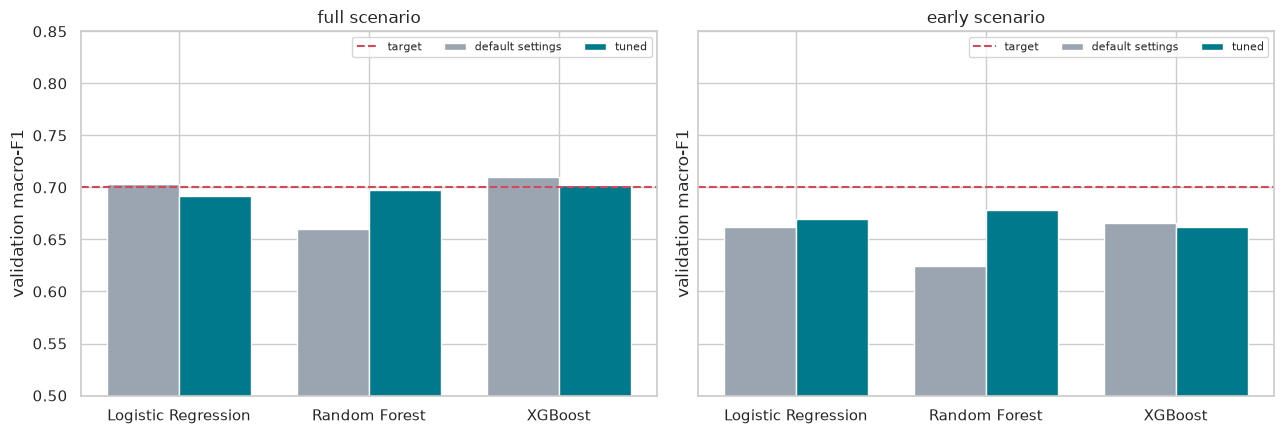

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, scen in zip(axes, SCEN):
    d = cmp[cmp.scenario == scen]
    x = np.arange(len(d)); w = 0.38
    ax.bar(x - w/2, d["default_val_macro_f1"], w, label="default settings", color="#9aa5b1")
    ax.bar(x + w/2, d["tuned_val_macro_f1"], w, label="tuned", color="#00798c")
    ax.set_xticks(x); ax.set_xticklabels([m.split(" (")[0] for m in d["model"]])
    ax.axhline(TARGET_F1, color="#d1495b", ls="--", label="target")
    ax.set_ylim(0.5, 0.85); ax.set_title(f"{scen} scenario"); ax.set_ylabel("validation macro-F1")
    ax.legend(loc="upper right", ncol=3, fontsize=8)
save("11_tuning_before_after")
plt.show()

### What tuning did (and did not) achieve
* **Random Forest improved a lot** (+0.037 full, +0.054 early). Most of that comes from the search choosing *class weights* and limiting tree depth.
* **Logistic Regression and XGBoost did not improve on validation** (full scenario: -0.011 and -0.008), even though their *cross-validation* scores were better than the untuned ones. Why? These tiny differences are inside the noise of a 664-student validation set, and the search optimised the cross-validation score, not the validation score. In plain words: **the defaults were already close to the best these models can do on this data**, so careful tuning gave diminishing returns.
* **Tuned Random Forest still memorises the training data** (training macro-F1 0.99 vs 0.70 on validation). Its validation score is competitive, but this gap is a warning sign and we will watch it on the test set.
* **Lesson:** tuning is not guaranteed to help. Reporting this honestly is better than showing only improvements.

### How Bayesian optimisation behaved
Each dot is one Optuna trial (one setting combination); the line is the best score found so far. A rising-then-flattening line means the search is homing in on a good region.

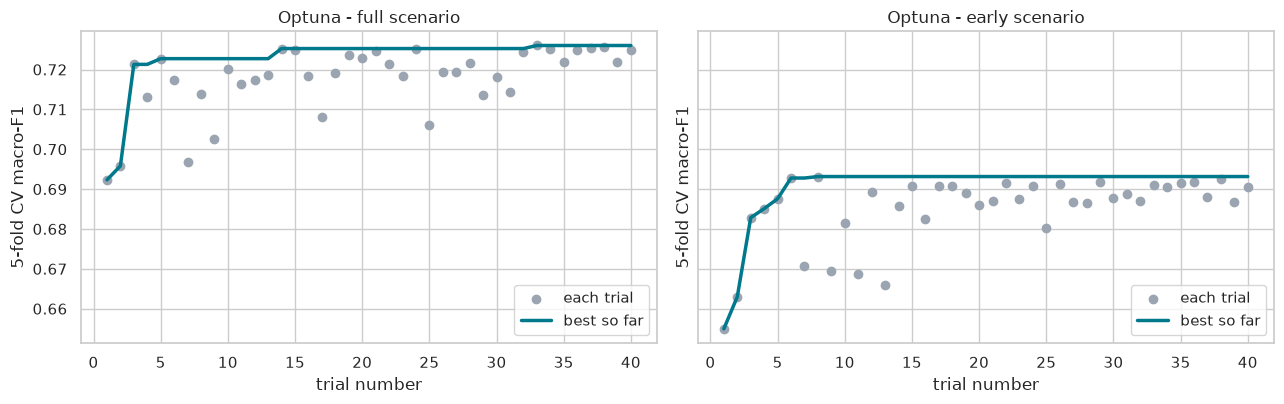

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, scen in zip(axes, SCEN):
    vals = [t.value for t in tuned[(scen, "_study")].trials]
    ax.scatter(range(1, len(vals) + 1), vals, color="#9aa5b1", label="each trial")
    ax.plot(range(1, len(vals) + 1), np.maximum.accumulate(vals), color="#00798c", lw=2.5, label="best so far")
    ax.set_title(f"Optuna - {scen} scenario"); ax.set_xlabel("trial number"); ax.set_ylabel("5-fold CV macro-F1")
    ax.legend(loc="lower right")
save("12_optuna_history")
plt.show()

---
## 6.x Choosing the best model for each scenario
We pick, for each scenario, the tuned model with the highest **validation macro-F1**, then look at it closely: the confusion matrix, per-class report, ROC curves and the features it relies on.

In [12]:
best = {}
for scen in SCEN:
    cand = cmp[cmp.scenario == scen].sort_values("tuned_val_macro_f1", ascending=False)
    best[scen] = cand.iloc[0]["model"]
    print(f"{scen:>5} scenario -> best model: {best[scen]}  (validation macro-F1 = {cand.iloc[0]['tuned_val_macro_f1']:.3f})")

 full scenario -> best model: XGBoost (Optuna)  (validation macro-F1 = 0.702)
early scenario -> best model: Random Forest (Random)  (validation macro-F1 = 0.679)


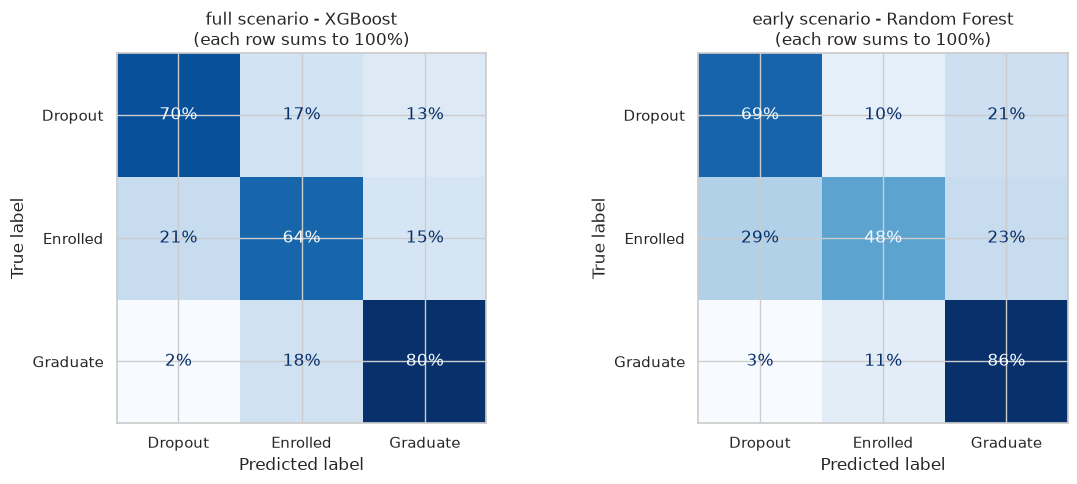


===== full scenario: XGBoost (Optuna) (validation set) =====
              precision    recall  f1-score   support

     Dropout      0.820     0.704     0.758       213
    Enrolled      0.444     0.639     0.524       119
    Graduate      0.855     0.798     0.826       332

    accuracy                          0.739       664
   macro avg      0.706     0.714     0.702       664
weighted avg      0.770     0.739     0.750       664


===== early scenario: Random Forest (Random) (validation set) =====
              precision    recall  f1-score   support

     Dropout      0.766     0.690     0.726       213
    Enrolled      0.487     0.479     0.483       119
    Graduate      0.800     0.855     0.827       332

    accuracy                          0.735       664
   macro avg      0.684     0.675     0.679       664
weighted avg      0.733     0.735     0.733       664



In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, scen in zip(axes, SCEN):
    cols, pipe = SCEN[scen], tuned[(scen, best[scen])]
    pred = pipe.predict(X_val[cols])
    ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=CLASSES, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{scen} scenario - {best[scen].split(' (')[0]}\n(each row sums to 100%)")
save("13_confusion_matrices")
plt.show()

for scen in SCEN:
    cols, pipe = SCEN[scen], tuned[(scen, best[scen])]
    print(f"\n===== {scen} scenario: {best[scen]} (validation set) =====")
    print(classification_report(y_val, pipe.predict(X_val[cols]), target_names=CLASSES, digits=3))

**Reading a confusion matrix:** the diagonal (top-left to bottom-right) is the percentage of each true group that was classified correctly. Off-diagonal cells are mistakes. The *Enrolled* class is usually hardest: these students are "in between" - still studying, neither dropped nor graduated - so they look similar to both other groups.

### ROC curves (one-vs-rest)
Each curve shows one class against all others. The closer a curve hugs the top-left corner, the better; the diagonal dashed line is random guessing.

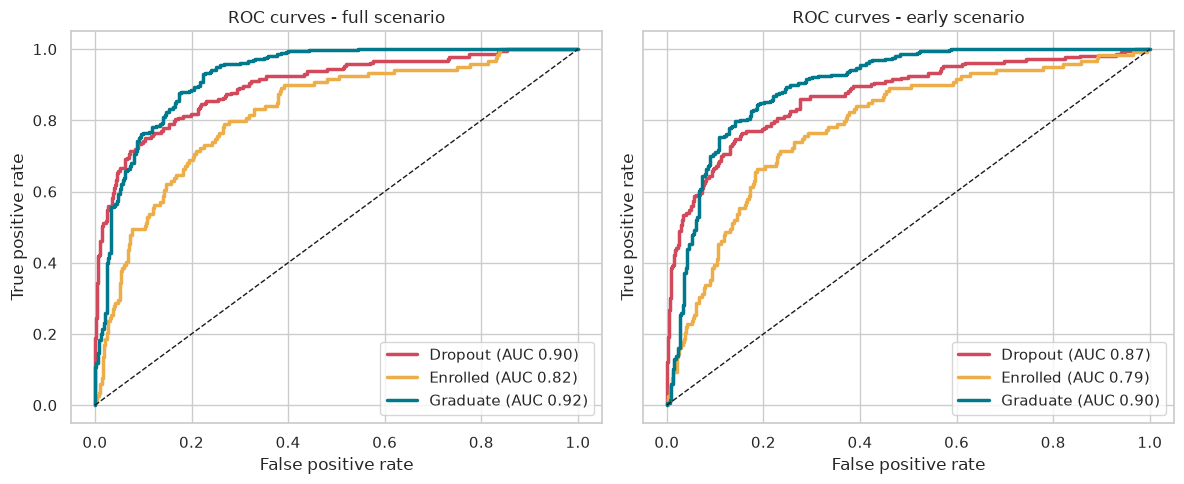

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, scen in zip(axes, SCEN):
    cols, pipe = SCEN[scen], tuned[(scen, best[scen])]
    proba = pipe.predict_proba(X_val[cols])
    for i, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve((y_val == i).astype(int), proba[:, i])
        auc = roc_auc_score((y_val == i).astype(int), proba[:, i])
        ax.plot(fpr, tpr, color=PALETTE[c], lw=2.5, label=f"{c} (AUC {auc:.2f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"ROC curves - {scen} scenario"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
save("14_roc_curves")
plt.show()

### Which features does the model rely on? (permutation importance)
**Permutation importance** shuffles one feature at a time on the validation set and measures how much the score *drops*. A big drop means the model depends heavily on that feature. It works for any model and is computed on the **original** columns (so a feature such as `course` is judged as one unit, not as 17 one-hot columns).

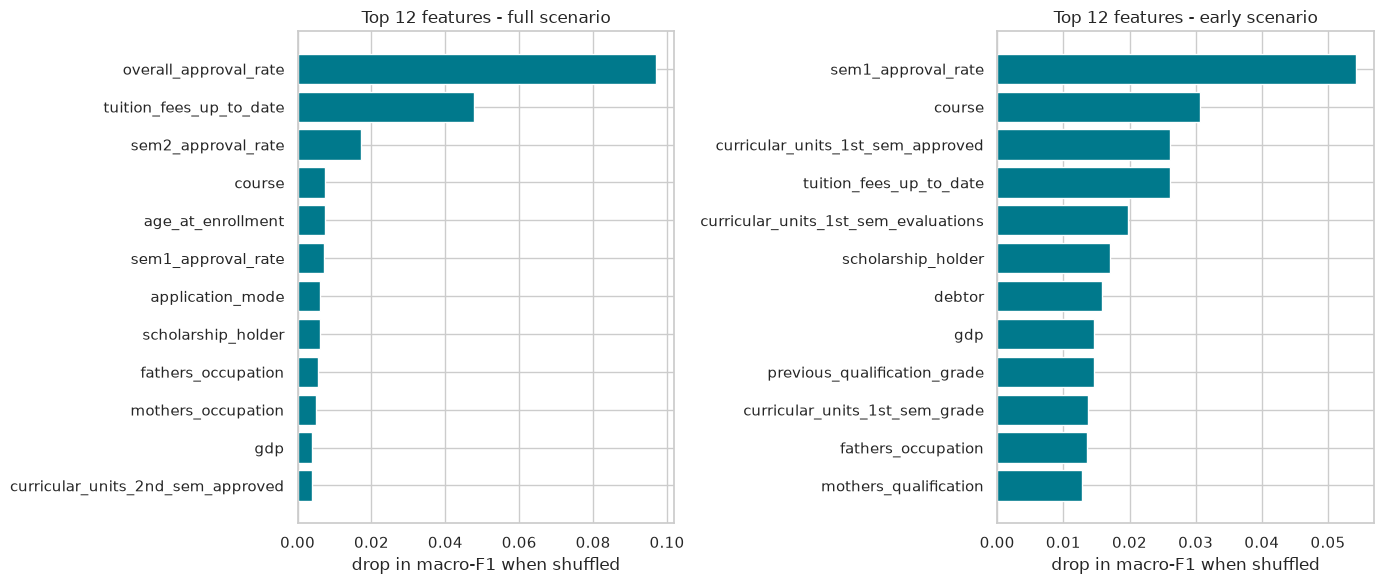

(overall_approval_rate      0.097
 tuition_fees_up_to_date    0.048
 sem2_approval_rate         0.017
 course                     0.008
 age_at_enrollment          0.007
 sem1_approval_rate         0.007
 dtype: float64,
 sem1_approval_rate                      0.054
 course                                  0.031
 curricular_units_1st_sem_approved       0.026
 tuition_fees_up_to_date                 0.026
 curricular_units_1st_sem_evaluations    0.020
 scholarship_holder                      0.017
 dtype: float64)

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
imp_tables = {}
for ax, scen in zip(axes, SCEN):
    cols, pipe = SCEN[scen], tuned[(scen, best[scen])]
    pi = permutation_importance(pipe, X_val[cols], y_val, scoring="f1_macro", n_repeats=8,
                                random_state=SEED, n_jobs=NJ)
    imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
    imp_tables[scen] = imp
    top = imp.head(12)[::-1]
    ax.barh(top.index, top.values, color="#00798c")
    ax.set_title(f"Top 12 features - {scen} scenario"); ax.set_xlabel("drop in macro-F1 when shuffled")
save("15_permutation_importance")
plt.show()
imp_tables["full"].head(6).round(3), imp_tables["early"].head(6).round(3)

---
## 6.y Fine-tuning the decision rule for Dropout (threshold)
By default the model picks the class with the **highest probability**. But missing a student who will drop out is the costly mistake. We can make the model more *sensitive* to Dropout: flag a student as Dropout whenever their Dropout probability is **at least a threshold t** (lower t = flag more students).
* Lower t -> **higher recall** (we catch more at-risk students) but **lower precision** (more false alarms).
* This is a trade-off a university would decide with its advisors' capacity in mind.

We scan t on the **validation** set and choose the t with the best macro-F1 among those that reach our recall target of 0.75 (if none does, the one with the best macro-F1).

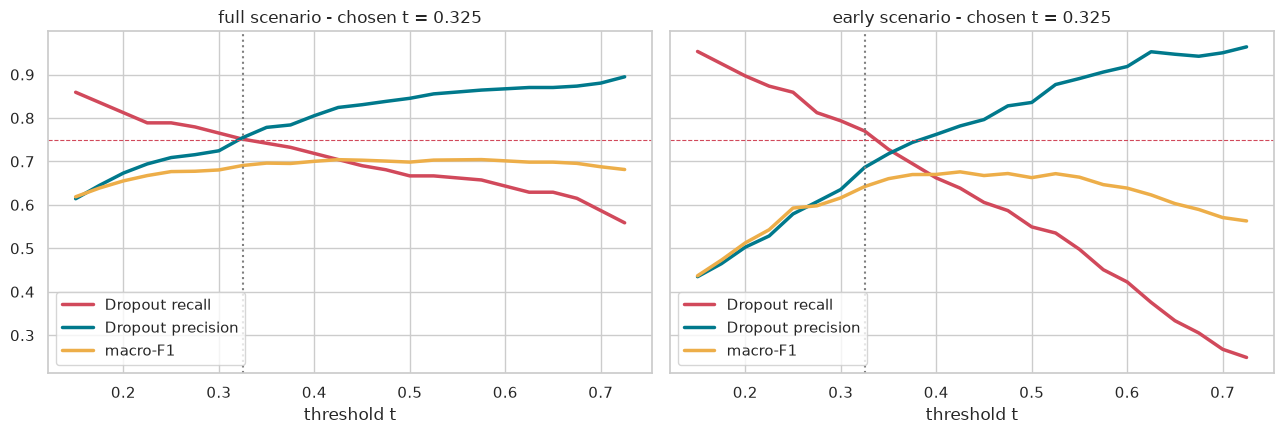

full -> {'t': 0.325, 'dropout_recall': 0.751, 'dropout_precision': 0.755, 'macro_f1': 0.691}
early -> {'t': 0.325, 'dropout_recall': 0.77, 'dropout_precision': 0.686, 'macro_f1': 0.642}


In [16]:
def predict_with_threshold(proba, t):
    """Dropout if P(Dropout) >= t, otherwise the more likely of the other two classes."""
    pred = proba[:, 1:].argmax(axis=1) + 1
    pred[proba[:, 0] >= t] = 0
    return pred

ts = np.round(np.arange(0.15, 0.75, 0.025), 3)
thr_choice, thr_tables = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, scen in zip(axes, SCEN):
    cols, pipe = SCEN[scen], tuned[(scen, best[scen])]
    proba = pipe.predict_proba(X_val[cols])
    tab = pd.DataFrame({
        "t": ts,
        "dropout_recall": [recall_score(y_val, predict_with_threshold(proba, t), labels=[0], average=None)[0] for t in ts],
        "dropout_precision": [precision_score(y_val, predict_with_threshold(proba, t), labels=[0], average=None, zero_division=0)[0] for t in ts],
        "macro_f1": [f1_score(y_val, predict_with_threshold(proba, t), average="macro") for t in ts]})
    ok = tab[tab.dropout_recall >= TARGET_RECALL]
    chosen = (ok if len(ok) else tab).sort_values("macro_f1", ascending=False).iloc[0]
    thr_choice[scen], thr_tables[scen] = float(chosen["t"]), tab
    ax.plot(tab.t, tab.dropout_recall, color="#d1495b", lw=2.5, label="Dropout recall")
    ax.plot(tab.t, tab.dropout_precision, color="#00798c", lw=2.5, label="Dropout precision")
    ax.plot(tab.t, tab.macro_f1, color="#edae49", lw=2.5, label="macro-F1")
    ax.axvline(chosen["t"], color="grey", ls=":"); ax.axhline(TARGET_RECALL, color="#d1495b", ls="--", lw=0.8)
    ax.set_title(f"{scen} scenario - chosen t = {chosen['t']:.3f}"); ax.set_xlabel("threshold t")
    ax.legend(loc="lower left")
save("16_threshold_tradeoff")
plt.show()
for scen in SCEN:
    row = thr_tables[scen][thr_tables[scen].t == thr_choice[scen]].round(3).to_dict("records")[0]
    print(scen, "->", row)

---
## Final validation scorecard
Compare against the success criteria we set in Notebook 1: **macro-F1 >= 0.70** and **Dropout recall >= 0.75**.

In [17]:
score = []
for scen in SCEN:
    cols, pipe = SCEN[scen], tuned[(scen, best[scen])]
    proba = pipe.predict_proba(X_val[cols])
    for label, pred in [("default rule (argmax)", proba.argmax(axis=1)),
                        (f"threshold t={thr_choice[scen]}", predict_with_threshold(proba, thr_choice[scen]))]:
        score.append({"scenario": scen, "model": best[scen], "decision rule": label,
                      "accuracy": accuracy_score(y_val, pred),
                      "macro_f1": f1_score(y_val, pred, average="macro"),
                      "dropout_recall": recall_score(y_val, pred, labels=[0], average=None)[0],
                      "dropout_precision": precision_score(y_val, pred, labels=[0], average=None)[0],
                      "roc_auc": roc_auc_score(y_val, proba, multi_class="ovr", average="macro")})
score = pd.DataFrame(score)
score["meets F1 target"] = score["macro_f1"] >= TARGET_F1
score["meets recall target"] = score["dropout_recall"] >= TARGET_RECALL
score.round(3)

,scenario,model,decision rule,accuracy,macro_f1,dropout_recall,dropout_precision,roc_auc,meets F1 target,meets recall target
0,full,XGBoost (Optuna),default rule (argmax),0.739,0.702,0.704,0.820,0.881,True,False
1,full,XGBoost (Optuna),threshold t=0.325,0.735,0.691,0.751,0.755,0.881,False,True
2,early,Random Forest (Random),default rule (argmax),0.735,0.679,0.690,0.766,0.852,False,False
3,early,Random Forest (Random),threshold t=0.325,0.718,0.642,0.770,0.686,0.852,False,True


### Honest conclusions of Notebook 2
| | Full scenario | Early-warning scenario |
|---|---|---|
| Best tuned model | XGBoost | Random Forest |
| Validation macro-F1 (default rule) | **0.702** (target 0.70 - just met) | 0.679 (target missed) |
| Validation Dropout recall (default rule) | 0.704 (target 0.75 - missed) | 0.690 (missed) |
| With lowered threshold t = 0.325 | recall 0.751 (met) but macro-F1 0.691 (missed) | recall 0.770 (met) but macro-F1 0.642 (missed) |

1. **No setting meets both targets at once.** Raising Dropout recall costs overall macro-F1, because we then label more "Enrolled"/"Graduate" students as Dropout. We must decide which matters more; for an early-warning use case, catching at-risk students (recall) is usually worth some false alarms.
2. **"Enrolled" is the weak class** (F1 about 0.52 full / 0.48 early; precision only 0.44-0.49). These students are in between - still studying, neither graduated nor dropped out - so they look like both other groups. This is the main reason macro-F1 stays near 0.70.
3. **Most important features.** Full scenario: `overall_approval_rate` (0.097) and `tuition_fees_up_to_date` (0.048) are far ahead. Early scenario: `sem1_approval_rate` (0.054), `course` (0.031), 1st-semester approved units and tuition status (0.026 each). Remember that correlated features *share* credit, so each one individually looks smaller than the group's true importance.
4. **Early warning is realistic.** Using only 1st-semester information costs about 0.02-0.04 macro-F1 versus waiting for 2nd-semester results - an encouraging trade-off.
5. **Caveats.** (a) The "best model" choice among the top candidates is practically a tie, so please do not read it as a strong ranking. (b) The threshold was chosen on the validation set and is evaluated here on the same set, so these numbers are a little optimistic. **The untouched test set in Notebook 3 gives the unbiased result.**

### Saving results for Notebook 3
We save, for each scenario: the **unfitted** best pipeline (so Notebook 3 can retrain it on train + validation), the **fitted** one, the chosen threshold, and whether it needs balanced sample weights.

In [18]:
config = {}
for scen in SCEN:
    name = best[scen]
    pipe = tuned[(scen, name)]
    joblib.dump(pipe, MODELS / f"{scen}_fitted_on_train.joblib")
    joblib.dump(clone(pipe), MODELS / f"{scen}_unfitted.joblib")
    row = tl[(tl.scenario == scen) & (tl.model == name)].iloc[0]
    params = row.params
    config[scen] = {"model": name, "features": SCEN[scen], "threshold": thr_choice[scen],
                    "balanced_sample_weights": bool(params.get("balanced", False)) if name.startswith("XGBoost") else False,
                    "best_params": {k: (v.item() if hasattr(v, "item") else v) for k, v in params.items()},
                    "cv_macro_f1": float(row.cv_macro_f1)}
json.dump(config, open(MODELS / "config.json", "w"), indent=2, default=str)
res.to_csv(MODELS / "model_comparison_default.csv", index=False)
cmp.to_csv(MODELS / "tuning_comparison.csv", index=False)
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['config.json', 'early_fitted_on_train.joblib', 'early_unfitted.joblib', 'full_fitted_on_train.joblib', 'full_unfitted.joblib', 'model_comparison_default.csv', 'tuning_comparison.csv']


---
# Glossary (new terms in this notebook)
* **Baseline:** the simplest possible predictor; every real model must beat it.
* **Hyperparameter:** a setting chosen *before* training (e.g. number of trees). **Parameter:** a value the model learns itself.
* **Pipeline:** preprocessing and model chained as one object so the same steps are always applied in the same order.
* **Cross-validation:** repeatedly training on part of the training data and testing on the rest, to get a stable score without touching the validation/test sets.
* **Underfitting / Overfitting:** too simple to learn the pattern / so complex it memorises noise.
* **Precision / Recall / F1:** accuracy of the positive predictions / share of real positives found / the balance of both.
* **Macro average:** average of per-class scores, each class counting equally.
* **ROC-AUC:** ranking quality of the predicted probabilities (0.5 = random, 1 = perfect).
* **Class weights:** telling the model that mistakes on rare classes cost more.
* **Threshold:** the probability above which we raise an alarm.
* **Permutation importance:** how much the score drops when a feature's values are shuffled.